(sec-1-3)=
# 1.3 From Body to Computer: The Acquisition Chain

The previous section ended with a millivolt-sized potential on the skin of the chest. Before that potential becomes a column of numbers in a file, it has to cross the boundary between the ionic world of the body and the electronic world of the instrument, be amplified about a thousand times, be cleaned of a common-mode voltage from the mains wiring that is often far larger than the ECG itself, be band-limited, and finally be sampled and quantized. Each of these steps leaves fingerprints on the recorded signal. Baseline drift, 50 or 60 Hz hum, clipped R peaks, a distorted ST segment: most of the artifacts that later chapters remove were either created or allowed through somewhere in this chain.

I want you to be able to look at a recording and guess which stage of the chain produced a given artifact. So in this section we follow the signal from the body to the computer one stage at a time. We start with the sensors themselves, model the electrode–skin interface as a small circuit and derive its impedance, then derive the common-mode rejection ratio of a differential amplifier and see what 60 dB and 100 dB of rejection mean for a real ECG. Decibels, gain and dynamic range come next, followed by a first look at analog filtering and sampling. The section closes with a step-by-step simulation of a complete ECG front end, driven by a real recording from the MIT-BIH Arrhythmia Database.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal
from matplotlib.patches import FancyBboxPatch

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)

(sec-1-3-1)=
## 1.3.1 The Chain at a Glance

Almost every biomedical recording system, from a hospital electrocardiograph to a smartwatch, follows the same sequence of stages {cite:p}`webster2010`. A **sensor** converts a physiological quantity into an electrical one. For bioelectric signals the sensor is an electrode, which converts ionic current in the tissue into electronic current in a wire. An **amplifier** raises the tiny voltage to a level the rest of the electronics can handle, and it must do so while rejecting interference that appears equally on both electrodes. **Analog filters** remove what the later stages cannot cope with: the slowly varying electrode offset (a high-pass filter) and everything above half the sampling rate (the anti-aliasing low-pass filter). An **analog-to-digital converter** (ADC) then samples the signal at regular instants and rounds each sample to one of a finite set of levels. From there on, everything is software.

The diagram below shows the chain for a typical ECG front end, with the signal level at each point. The two gain stages separated by a high-pass filter are not an accident of drawing; we will see in [Section 1.3.5](#sec-1-3-5) why a single stage with a gain of 1000 would not work.

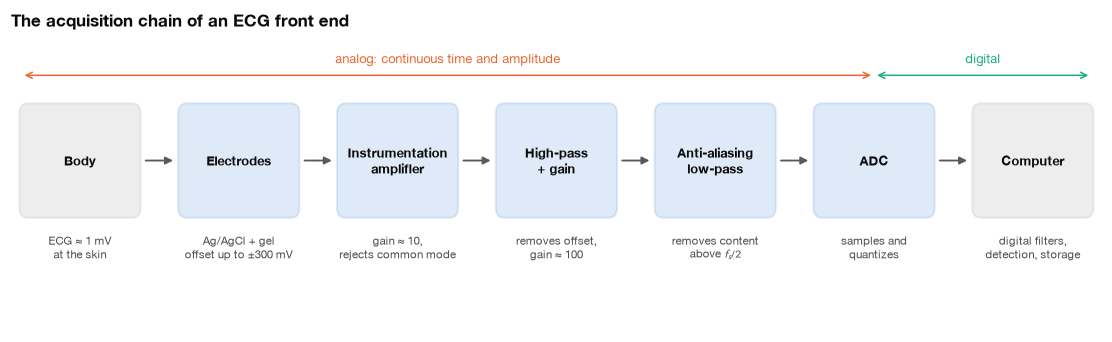

In [2]:
stages = [
    ("Body", "ECG ≈ 1 mV\nat the skin"),
    ("Electrodes", "Ag/AgCl + gel\noffset up to ±300 mV"),
    ("Instrumentation\namplifier", "gain ≈ 10,\nrejects common mode"),
    ("High-pass\n+ gain", "removes offset,\ngain ≈ 100"),
    ("Anti-aliasing\nlow-pass", "removes content\nabove $f_s/2$"),
    ("ADC", "samples and\nquantizes"),
    ("Computer", "digital filters,\ndetection, storage"),
]
w, h, gap = 1.12, 0.9, 0.4
fig, ax = plt.subplots(figsize=(10, 3.0))
for k, (name, note) in enumerate(stages):
    x = k * (w + gap)
    color = "0.55" if k in (0, 6) else C[0]
    ax.add_patch(FancyBboxPatch((x, 0), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=color, alpha=0.15, edgecolor=color, lw=1.3))
    ax.text(x + w / 2, h / 2, name, ha="center", va="center", fontsize=8.5, fontweight="bold")
    ax.text(x + w / 2, -0.15, note, ha="center", va="top", fontsize=7.5, color="0.3")
    if k < len(stages) - 1:
        ax.annotate("", xy=(x + w + gap - 0.04, h / 2), xytext=(x + w + 0.04, h / 2),
                    arrowprops=dict(arrowstyle="-|>", color="0.35", lw=1.2))
x_adc = 5 * (w + gap) + w / 2
ax.annotate("", xy=(0, 1.15), xytext=(x_adc, 1.15), arrowprops=dict(arrowstyle="<->", color=C[1], lw=1))
ax.annotate("", xy=(x_adc, 1.15), xytext=(6 * (w + gap) + w, 1.15),
            arrowprops=dict(arrowstyle="<->", color=C[2], lw=1))
ax.text(x_adc / 2, 1.25, "analog: continuous time and amplitude", ha="center", fontsize=8.5, color=C[1])
ax.text((x_adc + 6 * (w + gap) + w) / 2, 1.25, "digital", ha="center", fontsize=8.5, color=C[2])
ax.set(xlim=(-0.1, 7 * (w + gap) - gap + 0.1), ylim=(-0.95, 1.45),
       title="The acquisition chain of an ECG front end")
ax.axis("off")
plt.show()

The chain has a clear direction of information loss. Whatever the sensor does not capture is gone; whatever the amplifier saturates on is gone; whatever aliases in the ADC can never be separated from the true signal again. Digital processing can undo none of this, which is why it pays to understand the analog stages even if you will only ever work with recorded files.

(sec-1-3-2)=
## 1.3.2 Sensors: Turning Physiology into a Voltage

Electrodes are only one kind of sensor. Three others appear repeatedly in clinical monitoring, and each illustrates a different conversion principle.

**Pressure transducers.** Invasive blood pressure is measured through a fluid-filled catheter connected to a small chamber closed by a diaphragm. Strain gauges bonded to the diaphragm form a **Wheatstone bridge**: four resistors arranged so that, at zero pressure, the bridge is balanced and its output is zero. When pressure deflects the diaphragm, two gauges are stretched and two are compressed, and the bridge output becomes proportional to both the pressure and the excitation voltage $V_\text{ex}$ that powers the bridge. Disposable clinical transducers are standardized to a sensitivity of 5 µV per volt of excitation per mmHg. With a 5 V excitation, a pressure of 120 mmHg therefore produces

$$
v = 5\ \tfrac{\mu\text{V}}{\text{V}\cdot\text{mmHg}} \times 5\ \text{V} \times 120\ \text{mmHg} = 3.0\ \text{mV},
$$

a signal of the same order as the ECG, which needs the same kind of amplifier.

**Chemical sensors.** A glucose sensor of the kind used in continuous glucose monitors is an enzyme electrode, a design that goes back to {cite:t}`clark1962`. The enzyme glucose oxidase catalyzes the reaction of glucose with oxygen, producing gluconolactone and hydrogen peroxide. A platinum electrode held at a fixed positive potential oxidizes the peroxide and releases two electrons per molecule, so the sensor current, of the order of nanoamperes, grows with the glucose concentration $G$. The enzyme can only work so fast, and the current saturates according to Michaelis–Menten kinetics,

(eq-1-13)=
\begin{equation*}
i(G) = i_\text{max}\,\frac{G}{K_m + G}, \tag{1.13}
\end{equation*}

where $K_m$ is the concentration at which the current reaches half its maximum. For $G \ll K_m$ the denominator is close to $K_m$ and the response is nearly linear, $i \approx (i_\text{max}/K_m)\,G$. Sensor designers add outer membranes that limit how fast glucose reaches the enzyme, which raises the *apparent* $K_m$ well above the physiological range and keeps the response close to linear.

**Optical sensors.** A photoplethysmograph (PPG), the sensor of pulse oximeters and smartwatches, shines light from an LED into the tissue and measures the light that comes back (or through) with a photodiode. By the Beer–Lambert law, light of intensity $I_0$ crossing an absorbing layer of thickness $d$ emerges with intensity $I = I_0 e^{-\mu d}$, where $\mu$ is the absorption coefficient. With every heartbeat the arteries swell and the absorbing path through blood lengthens by a small $\Delta d(t)$, so

$$
I(t) = I_\text{DC}\,e^{-\mu_b \Delta d(t)} \approx I_\text{DC}\,\bigl(1 - \mu_b \Delta d(t)\bigr),
$$

using $e^{-x} \approx 1 - x$ for small $x$. The pulsatile ("AC") part rides on a large constant ("DC") part and is typically between a fraction of a percent and a few percent of it. The photodiode produces a current, which a **transimpedance amplifier** converts to a voltage $v = -i R_f$; with $R_f = 1$ MΩ, each microampere of photocurrent becomes one volt. The AC/DC structure of the PPG is the subject of Section 22.1.

The figure shows the three conversions with illustrative parameters. For the pressure transducer we drive the bridge with a synthetic arterial pressure waveform (80/120 mmHg, 72 beats per minute). For the glucose sensor we assume $i_\text{max} = 100$ nA and an apparent $K_m$ of 40 mmol/L. For the PPG we let the blood volume follow the same pressure pulse and set the pulsatile modulation to 2 % of the DC level.

In [3]:
def arterial_pressure(t, hr=72, p_dia=80.0, p_sys=120.0):
    """Synthetic arterial pressure (mmHg): fast upstroke, diastolic runoff and a dicrotic wave."""
    T = 60 / hr
    phase = t % T
    upstroke = 1 / (1 + np.exp(-(phase - 0.08) / 0.012))
    shape = upstroke * np.exp(-np.clip(phase - 0.11, 0, None) / 0.45)
    shape += 0.10 * np.exp(-0.5 * ((phase - 0.38) / 0.035) ** 2)
    end = (1 / (1 + np.exp(-(T - 0.08) / 0.012))) * np.exp(-(T - 0.11) / 0.45)
    shape -= (end - shape.min()) * phase / T            # make each beat end where it starts
    shape = (shape - shape.min()) / (shape.max() - shape.min())
    return p_dia + (p_sys - p_dia) * shape


fs_demo = 500
t_demo = np.arange(0, 3, 1 / fs_demo)
pressure = arterial_pressure(t_demo)
V_EX, SENS = 5.0, 5e-6                                  # V, V per V per mmHg
bridge_mV = 1e3 * SENS * V_EX * pressure

G = np.linspace(0, 30, 301)                             # glucose (mmol/L)
I_MAX, K_M = 100.0, 40.0                                # nA, mmol/L
i_glucose = I_MAX * G / (K_M + G)                       # equation (1.13)

pulse = (pressure - pressure.min()) / np.ptp(pressure)
ppg_percent = 100 * (1 - 0.02 * pulse)                  # photocurrent, % of DC level

print(f"Bridge output at 80 / 120 mmHg : {bridge_mV.min():.2f} / {bridge_mV.max():.2f} mV")
for g in (5, 10, 20):
    lin = I_MAX / K_M * g
    print(f"Glucose {g:2d} mmol/L: current {I_MAX * g / (K_M + g):5.1f} nA, "
          f"linear approximation {lin:5.1f} nA ({100 * (lin / (I_MAX * g / (K_M + g)) - 1):.0f} % high)")

Bridge output at 80 / 120 mmHg : 2.00 / 3.00 mV
Glucose  5 mmol/L: current  11.1 nA, linear approximation  12.5 nA (12 % high)
Glucose 10 mmol/L: current  20.0 nA, linear approximation  25.0 nA (25 % high)
Glucose 20 mmol/L: current  33.3 nA, linear approximation  50.0 nA (50 % high)


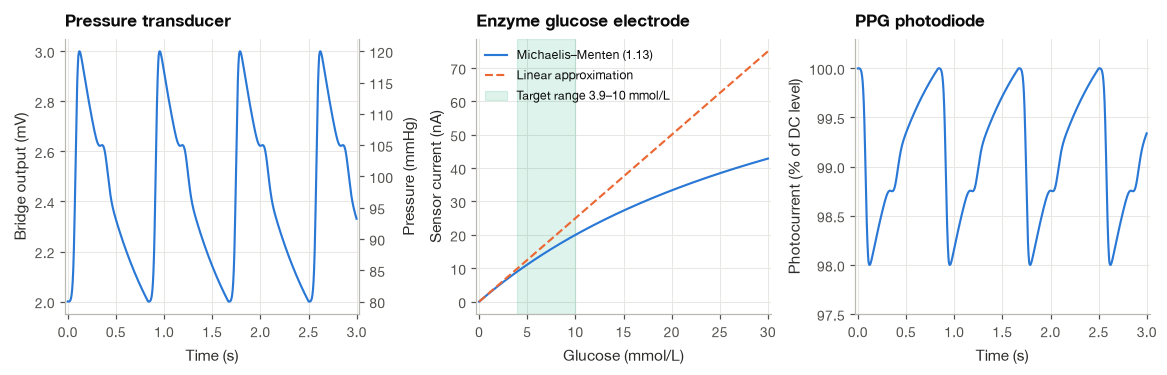

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3))
ax = axes[0]
ax.plot(t_demo, bridge_mV, color=C[0])
sec = ax.secondary_yaxis("right", functions=(lambda v: v / (1e3 * SENS * V_EX), lambda p: p * 1e3 * SENS * V_EX))
sec.set_ylabel("Pressure (mmHg)")
ax.set(xlabel="Time (s)", ylabel="Bridge output (mV)", title="Pressure transducer")

ax = axes[1]
ax.plot(G, i_glucose, color=C[0], label="Michaelis–Menten (1.13)")
ax.plot(G, I_MAX / K_M * G, color=C[1], ls="--", label="Linear approximation")
ax.axvspan(3.9, 10, color=C[2], alpha=0.15, label="Target range 3.9–10 mmol/L")
ax.set(xlabel="Glucose (mmol/L)", ylabel="Sensor current (nA)", title="Enzyme glucose electrode")
ax.legend(loc="upper left", fontsize=8)

ax = axes[2]
ax.plot(t_demo, ppg_percent, color=C[0])
ax.set(xlabel="Time (s)", ylabel="Photocurrent (% of DC level)", title="PPG photodiode", ylim=(97.5, 100.3))
plt.show()

The three panels make a point that is easy to forget: the physiological quantity and the measured quantity are related through a transfer curve, and that curve is linear only over a limited range. The bridge is linear for all practical pressures. The glucose electrode is not: with our parameters, the linear approximation overestimates the current by 25 % at 10 mmol/L, so the sensor must be calibrated with the curvature taken into account. The PPG is linear in the small pulsatile part, but that part is only 2 % of the total, so most of the ADC's range would be wasted on a constant unless the DC level is subtracted before amplification.

(sec-1-3-3)=
## 1.3.3 The Electrode–Skin Interface

In a wire, current is carried by electrons; in tissue and in electrode gel, by ions. At the surface of the electrode the two must be exchanged through a chemical reaction. For the silver/silver chloride (Ag/AgCl) electrode used almost universally for the ECG, the reaction is

$$
\text{Ag} + \text{Cl}^- \rightleftharpoons \text{AgCl} + e^- ,
$$

which runs easily in both directions, so the electrode passes current with little resistance. Two things happen at the interface. First, a **half-cell potential** appears, a DC voltage set by the electrochemistry (about +0.22 V for Ag/AgCl against the standard hydrogen electrode). The half-cell potentials of two identical electrodes cancel in a differential measurement, but real electrodes are never quite identical, and the skin adds potentials of its own, so a residual **electrode offset** of tens to hundreds of millivolts remains. ECG equipment is required to tolerate offsets of ±300 mV, more than a hundred times the ECG. Second, charges line up on both sides of the interface in a thin **double layer**, which behaves like a capacitor in parallel with a resistance for the charge-transfer reaction. The outermost layer of the skin, the dry and poorly conducting stratum corneum, adds a similar parallel resistance and capacitance, usually much larger than the electrode's own.

### An equivalent circuit

All of this can be lumped into a simple circuit {cite:p}`webster2010`: the half-cell potential $E_\text{hc}$ in series with a resistance $R_s$ (gel and deeper tissue) and a parallel combination of $R_d$ and $C_d$ (interface and skin). We now derive the impedance of this circuit at angular frequency $\omega$.

**Step 1: impedances of the elements.** A resistor has impedance $R$. A capacitor has impedance $1/(j\omega C)$: its current leads its voltage by 90°, which is exactly what multiplication by $j$ means (see [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb)).

**Step 2: the parallel branch.** For elements in parallel, admittances (reciprocals of impedances) add:

$$
\frac{1}{Z_p} = \frac{1}{R_d} + j\omega C_d = \frac{1 + j\omega R_d C_d}{R_d}
\quad\Longrightarrow\quad
Z_p = \frac{R_d}{1 + j\omega\tau}, \qquad \tau = R_d C_d .
$$

**Step 3: add the series resistance.** Impedances in series add, so the electrode impedance is

(eq-1-14)=
\begin{equation*}
Z_e(\omega) = R_s + \frac{R_d}{1 + j\omega\tau}. \tag{1.14}
\end{equation*}

**Step 4: separate real and imaginary parts.** Multiplying numerator and denominator of the fraction by the conjugate $1 - j\omega\tau$ makes the denominator real:

(eq-1-15)=
\begin{equation*}
Z_e(\omega) = R_s + \frac{R_d(1 - j\omega\tau)}{1 + \omega^2\tau^2}
= \underbrace{R_s + \frac{R_d}{1 + \omega^2\tau^2}}_{\operatorname{Re}\{Z_e\}}
\;-\; j\,\underbrace{\frac{\omega\tau R_d}{1 + \omega^2\tau^2}}_{-\operatorname{Im}\{Z_e\}}. \tag{1.15}
\end{equation*}

The limits are easy to read. At very low frequencies $\omega\tau \ll 1$, the capacitor is an open circuit and $Z_e \to R_s + R_d$. At very high frequencies $\omega\tau \gg 1$, the capacitor short-circuits $R_d$ and $Z_e \to R_s$. The transition happens around the corner frequency $f_c = 1/(2\pi\tau)$, where the imaginary part reaches its largest magnitude, $R_d/2$. The impedance is therefore highest exactly where the ECG has most of its energy, at a few hertz and below.

We use two illustrative sets of values: unprepared dry skin with $R_d = 200$ kΩ, and skin that has been cleaned and lightly abraded, which removes much of the stratum corneum, with $R_d = 10$ kΩ. In both cases $R_s = 500$ Ω and $C_d = 20$ nF. The code checks equation (1.15) against direct complex arithmetic on equation (1.14).

In [5]:
def electrode_impedance(f, R_s, R_d, C_d):
    """Impedance (ohm) of the electrode-skin model, equation (1.14)."""
    return R_s + R_d / (1 + 1j * 2 * np.pi * f * R_d * C_d)


skin = {"unprepared skin": dict(R_s=500.0, R_d=200e3, C_d=20e-9),
        "abraded skin": dict(R_s=500.0, R_d=10e3, C_d=20e-9)}
f = np.logspace(-2, 4, 400)

p = skin["unprepared skin"]
wt = 2 * np.pi * f * p["R_d"] * p["C_d"]
Z_direct = electrode_impedance(f, **p)
Z_parts = p["R_s"] + p["R_d"] / (1 + wt**2) - 1j * wt * p["R_d"] / (1 + wt**2)   # equation (1.15)
print(f"max |direct - (1.15)| = {np.abs(Z_direct - Z_parts).max():.1e} ohm")
for name, p in skin.items():
    fc = 1 / (2 * np.pi * p["R_d"] * p["C_d"])
    print(f"{name:16s}: f_c = {fc:6.1f} Hz,  |Z| at 1 Hz = {abs(electrode_impedance(1, **p)) / 1e3:6.1f} kohm,"
          f"  at 60 Hz = {abs(electrode_impedance(60, **p)) / 1e3:6.1f} kohm")

max |direct - (1.15)| = 4.1e-11 ohm
unprepared skin : f_c =   39.8 Hz,  |Z| at 1 Hz =  200.4 kohm,  at 60 Hz =  110.8 kohm
abraded skin    : f_c =  795.8 Hz,  |Z| at 1 Hz =   10.5 kohm,  at 60 Hz =   10.5 kohm


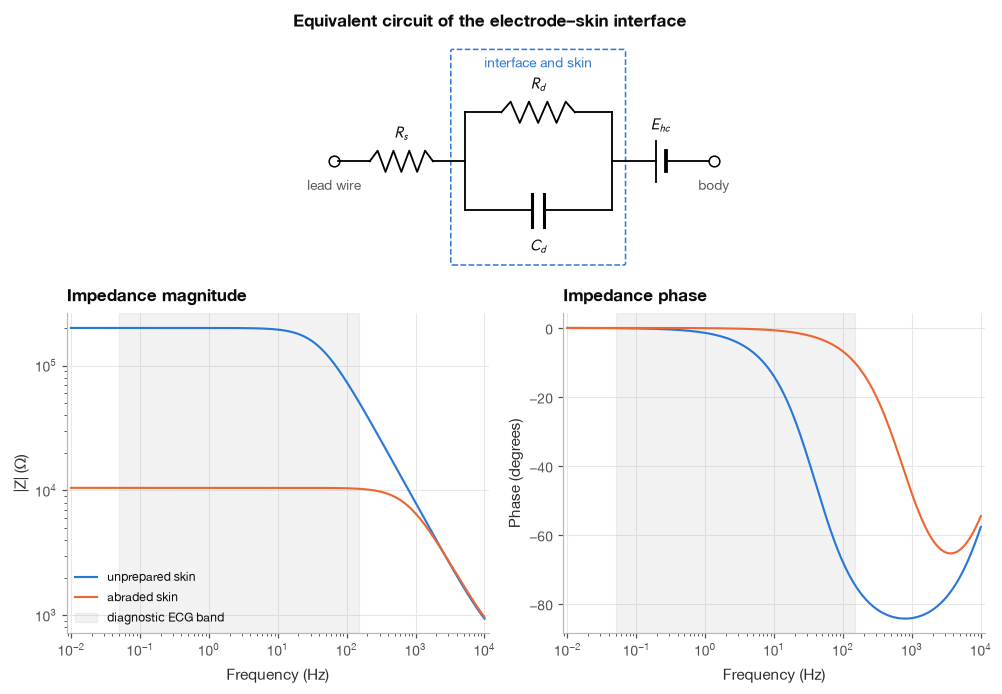

In [6]:
def draw_resistor(ax, x0, x1, y, label, dy=0.28):
    a, b = x0 + 0.25 * (x1 - x0), x1 - 0.25 * (x1 - x0)
    zx = np.linspace(a, b, 9)
    zy = y + 0.13 * np.array([0, 1, -1, 1, -1, 1, -1, 1, 0])
    ax.plot([x0, a], [y, y], "k", lw=1.2)
    ax.plot(zx, zy, "k", lw=1.2)
    ax.plot([b, x1], [y, y], "k", lw=1.2)
    ax.text((x0 + x1) / 2, y + dy, label, ha="center", fontsize=10)


def draw_capacitor(ax, x0, x1, y, label):
    m, g = (x0 + x1) / 2, 0.07
    ax.plot([x0, m - g], [y, y], "k", lw=1.2)
    ax.plot([m + g, x1], [y, y], "k", lw=1.2)
    for xp in (m - g, m + g):
        ax.plot([xp, xp], [y - 0.2, y + 0.2], "k", lw=2)
    ax.text(m, y - 0.5, label, ha="center", fontsize=10)


def draw_cell(ax, x0, x1, y, label):
    m = (x0 + x1) / 2
    ax.plot([x0, m - 0.06], [y, y], "k", lw=1.2)
    ax.plot([m + 0.06, x1], [y, y], "k", lw=1.2)
    ax.plot([m - 0.06, m - 0.06], [y - 0.25, y + 0.25], "k", lw=1.2)
    ax.plot([m + 0.06, m + 0.06], [y - 0.12, y + 0.12], "k", lw=2.5)
    ax.text(m, y + 0.38, label, ha="center", fontsize=10)


fig = plt.figure(figsize=(9, 6.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.35])
ax = fig.add_subplot(gs[0, :])
ax.plot(0, 0, "o", ms=7, mfc="white", mec="k")
draw_resistor(ax, 0.05, 1.6, 0, "$R_s$")
ax.plot([1.6, 1.6], [-0.6, 0.6], "k", lw=1.2)
draw_resistor(ax, 1.6, 3.4, 0.6, "$R_d$")
draw_capacitor(ax, 1.6, 3.4, -0.6, "$C_d$")
ax.plot([3.4, 3.4], [-0.6, 0.6], "k", lw=1.2)
draw_cell(ax, 3.4, 4.6, 0, "$E_{hc}$")
ax.plot(4.65, 0, "o", ms=7, mfc="white", mec="k")
ax.text(0, -0.35, "lead wire", ha="center", fontsize=9, color="0.35")
ax.text(4.65, -0.35, "body", ha="center", fontsize=9, color="0.35")
ax.text(2.5, 1.15, "interface and skin", ha="center", fontsize=9, color=C[0])
ax.add_patch(FancyBboxPatch((1.45, -1.25), 2.1, 2.6, boxstyle="round,pad=0.02", fill=False,
                            edgecolor=C[0], ls="--", lw=1))
ax.set(xlim=(-0.5, 5.2), ylim=(-1.4, 1.5), title="Equivalent circuit of the electrode–skin interface")
ax.set_aspect("equal")
ax.axis("off")

ax_m = fig.add_subplot(gs[1, 0])
ax_p = fig.add_subplot(gs[1, 1])
for k, (name, p) in enumerate(skin.items()):
    Z = electrode_impedance(f, **p)
    ax_m.loglog(f, np.abs(Z), color=C[k], label=name)
    ax_p.semilogx(f, np.degrees(np.angle(Z)), color=C[k], label=name)
for ax in (ax_m, ax_p):
    ax.axvspan(0.05, 150, color="0.6", alpha=0.12, label="diagnostic ECG band")
ax_m.set(xlabel="Frequency (Hz)", ylabel="|Z| (Ω)", title="Impedance magnitude")
ax_p.set(xlabel="Frequency (Hz)", ylabel="Phase (degrees)", title="Impedance phase")
ax_m.legend(loc="lower left", fontsize=8)
plt.show()

### Why the amplifier needs a high input impedance

The electrodes and the amplifier form a voltage divider. If the ECG source drives current through two electrodes with impedances $Z_{e1}$ and $Z_{e2}$ into an amplifier whose differential input impedance is $Z_\text{in}$, only the fraction

(eq-1-16)=
\begin{equation*}
\frac{v_\text{measured}}{v_\text{ECG}} = \frac{Z_\text{in}}{Z_\text{in} + Z_{e1} + Z_{e2}} \tag{1.16}
\end{equation*}

reaches the amplifier. Because $Z_e$ depends on frequency, this fraction does too: an input impedance that is too low does not just attenuate the ECG, it *filters* it, removing more of the low frequencies (the P and T waves, the ST segment) than of the high ones. The table evaluates equation (1.16) for two unprepared electrodes and several amplifier input impedances.

In [7]:
p = skin["unprepared skin"]
rows = []
for Z_in in (100e3, 1e6, 10e6, 1e9):
    row = {"Z_in": f"{Z_in / 1e6:g} MΩ"}
    for f0 in (0.5, 10.0, 60.0):
        Ze = electrode_impedance(f0, **p)
        row[f"gain at {f0:g} Hz"] = round(abs(Z_in / (Z_in + 2 * Ze)), 4)     # equation (1.16)
    rows.append(row)
pd.DataFrame(rows).set_index("Z_in")

,gain at 0.5 Hz,gain at 10 Hz,gain at 60 Hz
Z_in,,,
0.1 MΩ,0.1996,0.2055,0.3455
1 MΩ,0.7138,0.7244,0.8786
10 MΩ,0.9615,0.9636,0.9877
1000 MΩ,0.9996,0.9996,0.9999


With a 100 kΩ input the ECG at 0.5 Hz would be cut to a fifth of its size while its 60 Hz components lose much less, a severe distortion. At 10 MΩ the error is a few percent at the lowest frequencies, and at 1 GΩ it is negligible. This is why ECG amplifiers have input impedances of many megaohms, and why dry electrodes, whose impedance can be much larger than that of gelled ones, need even higher input impedances.

(sec-1-3-4)=
## 1.3.4 The Differential Amplifier and Common-Mode Rejection

The body is a conductor surrounded by mains wiring. Through the small capacitance between the body and nearby cables, a displacement current at 50 or 60 Hz flows into the body and out through whatever path to ground it finds, and the whole body rises and falls by a voltage that can be many times larger than the ECG. I use 60 Hz throughout this section, the mains frequency in Taiwan and North America (and of the MIT-BIH recordings, made in Boston); in Europe and most of Asia it is 50 Hz.

The key observation is that this interference appears almost identically at every electrode, whereas the ECG differs between electrodes. An amplifier that responds only to the *difference* between its two inputs can therefore separate them.

### Differential and common-mode signals

Any pair of input voltages $v_+$ and $v_-$ can be rewritten as a **differential** part and a **common-mode** part,

$$
v_d = v_+ - v_-, \qquad v_{cm} = \frac{v_+ + v_-}{2},
\qquad\text{so that}\qquad v_\pm = v_{cm} \pm \frac{v_d}{2}.
$$

The ECG lives in $v_d$; the mains interference lives mostly in $v_{cm}$.

### Deriving the common-mode gain

An ideal differential amplifier computes $A(v_+ - v_-)$. A real one amplifies its two inputs with slightly different gains, $A_1$ and $A_2$, because its components are never perfectly matched. We write its output and substitute $v_\pm = v_{cm} \pm v_d/2$:

$$
\begin{aligned}
v_o &= A_1 v_+ - A_2 v_- \\
    &= A_1\left(v_{cm} + \frac{v_d}{2}\right) - A_2\left(v_{cm} - \frac{v_d}{2}\right) \\
    &= \frac{A_1 + A_2}{2}\, v_d \;+\; (A_1 - A_2)\, v_{cm}.
\end{aligned}
$$

The output is thus a sum of an amplified differential signal and an amplified common-mode signal,

(eq-1-17)=
\begin{equation*}
v_o = A_d\, v_d + A_{cm}\, v_{cm}, \qquad A_d = \frac{A_1 + A_2}{2}, \quad A_{cm} = A_1 - A_2 . \tag{1.17}
\end{equation*}

The **common-mode rejection ratio** measures how much more the amplifier amplifies the wanted difference than the unwanted common mode:

(eq-1-18)=
\begin{equation*}
\text{CMRR} = \left|\frac{A_d}{A_{cm}}\right|, \qquad \text{CMRR}_\text{dB} = 20\log_{10}\left|\frac{A_d}{A_{cm}}\right|. \tag{1.18}
\end{equation*}

Dividing equation (1.17) by $A_d$ refers the output back to the input, where it can be compared directly with the ECG:

$$
\frac{v_o}{A_d} = v_d + \frac{A_{cm}}{A_d}\, v_{cm} \quad\Longrightarrow\quad
\text{input-referred interference} = \frac{v_{cm}}{\text{CMRR}} \ \text{(in magnitude)}.
$$

**Example 1.3.1.** Two gains of nominally 1000 differ by 0.1 %, $A_1 = 1000.5$ and $A_2 = 999.5$. Then $A_d = 1000$, $A_{cm} = 1$, and $\text{CMRR} = 1000$, or $20\log_{10}1000 = 60$ dB. A common-mode voltage of 100 mV appears at the output as if a differential signal of $100\ \text{mV}/1000 = 0.1$ mV had been applied, a tenth of the R wave. To make the interference 1 µV we need $\text{CMRR} = 10^5$, i.e. 100 dB, which corresponds to gains matched to one part in $10^5$. Discrete components cannot be matched that well, which is why integrated instrumentation amplifiers exist.

### The instrumentation amplifier

The standard solution uses three operational amplifiers. In the first stage, each input drives the non-inverting input of an op-amp, and the two op-amps are joined through a single gain resistor $R_G$ between their inverting inputs, with a feedback resistor $R_1$ from each output to its inverting input. An ideal op-amp in negative feedback holds its two inputs at the same voltage, so the inverting inputs sit at $v_+$ and $v_-$, and the voltage across $R_G$ is exactly $v_d$. The current $v_d/R_G$ flows through the chain $R_1$–$R_G$–$R_1$, so the voltage between the two outputs is

(eq-1-19)=
\begin{equation*}
v_{a} - v_{b} = \frac{v_d}{R_G}\,(R_1 + R_G + R_1) = \left(1 + \frac{2R_1}{R_G}\right) v_d . \tag{1.19}
\end{equation*}

A pure common-mode input, $v_+ = v_- = v_{cm}$, puts no voltage across $R_G$, no current flows, and both outputs simply follow $v_{cm}$ with gain one. The first stage therefore multiplies the differential signal by $G_1 = 1 + 2R_1/R_G$ while leaving the common mode untouched. A second-stage difference amplifier with its own imperfect rejection, $\text{CMRR}_2$, then sees a differential signal already $G_1$ times larger than before, so the overall rejection is about $G_1 \cdot \text{CMRR}_2$. Integrated instrumentation amplifiers routinely reach 100 to 120 dB at mains frequency.

### Simulating an ECG with mains interference

We now apply equation (1.17) to a real ECG. The first 10 s of MIT-BIH record 100 (lead MLII) play the role of the differential signal, and the body carries a 60 Hz common-mode voltage of 100 mV amplitude, a plausible value when the reference electrode makes poor contact. We compare an amplifier with a CMRR of 60 dB with one of 100 dB, and then measure the interference in each output with the phasor estimator of [Section 2.1.7](../ch02_math_toolkit/01_complex_numbers.ipynb), equation (2.3).

In [8]:
rec = wfdb.rdrecord("../data/mitdb/100", sampto=3600, channels=[0])
fs = rec.fs
ecg = rec.p_signal[:, 0]                                 # mV
t = np.arange(ecg.size) / fs
v_cm = 100.0 * np.cos(2 * np.pi * 60 * t)               # mV, 60 Hz common mode


def amplify_input_referred(v_d, v_cm, cmrr_db):
    """Output of a differential amplifier divided by A_d, equation (1.17)."""
    return v_d + v_cm / 10 ** (cmrr_db / 20)


def phasor_at(x, f0, fs):
    """Complex amplitude of the f0 component of x, equation (2.3)."""
    n = np.arange(x.size)
    return 2 / x.size * np.sum(x * np.exp(-2j * np.pi * f0 * n / fs))


outputs = {db: amplify_input_referred(ecg, v_cm, db) for db in (60, 100)}
for db, y in outputs.items():
    measured = abs(phasor_at(y - ecg, 60, fs)) * 1000
    print(f"CMRR {db:3d} dB: predicted {1000 * 100 / 10 ** (db / 20):7.2f} µV, measured {measured:7.2f} µV")

CMRR  60 dB: predicted  100.00 µV, measured  100.00 µV
CMRR 100 dB: predicted    1.00 µV, measured    1.00 µV


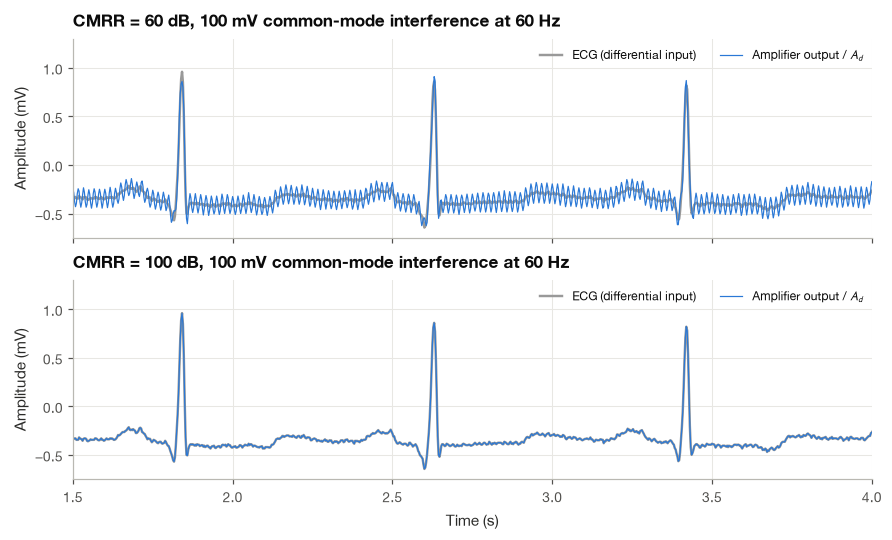

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, sharey=True)
for ax, (db, y) in zip(axes, outputs.items()):
    ax.plot(t, ecg, color="0.6", lw=1.6, label="ECG (differential input)")
    ax.plot(t, y, color=C[0], lw=0.8, label="Amplifier output / $A_d$")
    ax.set(ylabel="Amplitude (mV)", title=f"CMRR = {db} dB, 100 mV common-mode interference at 60 Hz")
    ax.legend(loc="upper right", ncols=2, fontsize=8)
axes[1].set(xlabel="Time (s)", xlim=(1.5, 4.0), ylim=(-0.75, 1.3))
plt.show()

At 60 dB the 0.1 mV of hum is plainly visible as a thick band along the baseline, large enough to obscure the P wave. At 100 dB it has shrunk to 1 µV and disappears under the line width. The estimator recovers the predicted amplitudes exactly, because the 10-s window holds a whole number of 60 Hz cycles.

### The weak link: unequal electrode impedances

A perfect amplifier does not guarantee a clean ECG. Each input has a finite **common-mode input impedance** $Z_{cm}$ to ground, and the common-mode voltage reaches each input through its own electrode. The two electrodes form two voltage dividers with $Z_{cm}$:

$$
v_+ = v_{cm}\,\frac{Z_{cm}}{Z_{cm} + Z_{e1}}, \qquad v_- = v_{cm}\,\frac{Z_{cm}}{Z_{cm} + Z_{e2}} .
$$

Subtracting and bringing the two fractions to a common denominator,

(eq-1-20)=
\begin{equation*}
v_+ - v_- = v_{cm}\,\frac{Z_{cm}\,(Z_{e2} - Z_{e1})}{(Z_{cm} + Z_{e1})(Z_{cm} + Z_{e2})}
\;\approx\; v_{cm}\,\frac{Z_{e2} - Z_{e1}}{Z_{cm}}, \tag{1.20}
\end{equation*}

where the approximation uses $Z_{cm} \gg Z_{e1}, Z_{e2}$. Any imbalance between the electrodes turns part of the common-mode voltage into a genuine differential signal *before* the amplifier sees it, and no amount of CMRR can remove it afterwards. The table combines both mechanisms for $v_{cm} = 100$ mV and $Z_{cm} = 100$ MΩ, adding the two contributions as a worst case.

In [10]:
Z_CM = 100e6                                             # ohm
rows = []
for dZ in (0.0, 5e3, 20e3):
    row = {"electrode mismatch": f"{dZ / 1e3:g} kΩ"}
    for db in (60, 80, 100, 120):
        total_uV = 1e3 * 100.0 * (1 / 10 ** (db / 20) + dZ / Z_CM)       # (1.18) + (1.20)
        row[f"CMRR {db} dB"] = round(total_uV, 1)
    rows.append(row)
print("Input-referred 60 Hz interference (µV):")
pd.DataFrame(rows).set_index("electrode mismatch")

Input-referred 60 Hz interference (µV):


,CMRR 60 dB,CMRR 80 dB,CMRR 100 dB,CMRR 120 dB
electrode mismatch,,,,
0 kΩ,100.0,10.0,1.0,0.1
5 kΩ,105.0,15.0,6.0,5.1
20 kΩ,120.0,30.0,21.0,20.1


With a 20 kΩ mismatch, which is easily reached with unprepared skin, the interference stays near 20 µV however good the amplifier is; the mismatch alone limits the effective rejection to $20\log_{10}(Z_{cm}/\Delta Z) = 74$ dB. Careful skin preparation attacks the mismatch, and a third electrode attacks $v_{cm}$ itself: the **driven right leg** circuit senses the common-mode voltage, inverts and amplifies it, and feeds it back into the body through the right-leg electrode, reducing $v_{cm}$ by the loop gain {cite:p}`winter1983`. [Section 11.2](../ch17_ecg/02_recording_the_ecg.ipynb) returns to these circuits in the context of the 12-lead ECG, and Section 18.4 removes whatever hum survives them with digital filters.

(sec-1-3-5)=
## 1.3.5 Gain, Dynamic Range and Decibels

### Decibels

Signal levels in an acquisition chain span many orders of magnitude, from microvolts at the electrode to volts at the ADC, and gains multiply from stage to stage. A logarithmic unit turns both problems into simple addition. The **bel** is the base-10 logarithm of a *power* ratio, and the decibel is one tenth of it:

$$
L = 10\log_{10}\frac{P_2}{P_1}\ \text{dB}.
$$

Most of the time, though, we measure amplitudes (voltages), not powers. To convert, note that the power dissipated by a voltage $v$ across a resistance $R$ is $P = v^2/R$. For two voltages across the same resistance,

(eq-1-21)=
\begin{equation*}
L = 10\log_{10}\frac{v_2^2/R}{v_1^2/R} = 10\log_{10}\left(\frac{v_2}{v_1}\right)^2 = 20\log_{10}\frac{v_2}{v_1}\ \text{dB}. \tag{1.21}
\end{equation*}

The factor 20 is therefore not a separate definition: it is the factor 10 applied to a squared quantity. The rule to remember is $10\log_{10}$ for powers and energies, $20\log_{10}$ for amplitudes, and then a given physical situation has the same value in decibels whichever way it is computed. In signal processing the resistance is usually dropped and "power" simply means the mean square of a signal, a convention we formalize in Section 3.4. Gains in decibels add when stages are cascaded, because the logarithm of a product is the sum of the logarithms: a gain of 10 (20 dB) followed by a gain of 100 (40 dB) is a gain of 1000 (60 dB).

In [11]:
ratios = np.array([np.sqrt(2), 2, 10, 100, 1000, 1e5])
pd.DataFrame({"amplitude ratio": np.round(ratios, 3),
              "power ratio": np.round(ratios**2, 1),
              "dB from amplitudes (20 log10)": np.round(20 * np.log10(ratios), 2),
              "dB from powers (10 log10)": np.round(10 * np.log10(ratios**2), 2)}).set_index("amplitude ratio")

,power ratio,dB from amplitudes (20 log10),dB from powers (10 log10)
amplitude ratio,,,
1.414,2.000000e+00,3.01,3.01
2.000,4.000000e+00,6.02,6.02
10.000,1.000000e+02,20.00,20.00
100.000,1.000000e+04,40.00,40.00
1000.000,1.000000e+06,60.00,60.00
100000.000,1.000000e+10,100.00,100.00


A few values are worth knowing by heart: doubling an amplitude adds 6 dB, halving a power removes 3 dB, and every factor of ten in amplitude is 20 dB.

### Dynamic range of the ADC

An ADC with $N$ bits divides its full-scale range (FSR) into $2^N$ steps of size

$$
q = \frac{\text{FSR}}{2^N}.
$$

The ratio between the largest signal it can represent and the smallest step it can resolve is its **dynamic range**,

(eq-1-22)=
\begin{equation*}
\text{DR} = 20\log_{10}\frac{\text{FSR}}{q} = 20\log_{10} 2^N = N \cdot 20\log_{10}2 \approx 6.02\,N\ \text{dB}. \tag{1.22}
\end{equation*}

Each extra bit buys about 6 dB. Section 9.4 refines this by treating the rounding error as noise.

The MIT-BIH recordings were digitized with 11 bits over a 10 mV range {cite:p}`moody2001`. The record header stores this as a gain in ADC units per millivolt; Section 1.4 explains the header in detail. We read the gain, compute the step size, and check how much of the available range record 100 actually uses.

In [12]:
hdr = wfdb.rdheader("../data/mitdb/100")
digital = wfdb.rdrecord("../data/mitdb/100", channels=[0], physical=False).d_signal[:, 0]
q_uV = 1000 / hdr.adc_gain[0]
used = digital.max() - digital.min()
print(f"ADC resolution          : {hdr.adc_res[0]} bits, gain {hdr.adc_gain[0]:.0f} units/mV")
print(f"Step size q             : {q_uV:.1f} µV, full scale {2 ** hdr.adc_res[0] * q_uV / 1000:.2f} mV")
print(f"Dynamic range (1.22)    : {20 * np.log10(2 ** hdr.adc_res[0]):.1f} dB")
print(f"Codes used by MLII      : {used} of {2 ** hdr.adc_res[0]} ({100 * used / 2 ** hdr.adc_res[0]:.0f} %),"
      f" i.e. {used * q_uV / 1000:.2f} mV peak to peak over 30 min")

ADC resolution          : 11 bits, gain 200 units/mV
Step size q             : 5.0 µV, full scale 10.24 mV
Dynamic range (1.22)    : 66.2 dB
Codes used by MLII      : 830 of 2048 (41 %), i.e. 4.15 mV peak to peak over 30 min


Record 100 uses about 40 % of the available codes over half an hour, including its occasional artifacts. That is a sensible design: a margin of more than a factor of two protects against clipping when the baseline wanders or the patient moves, at the price of a little more than one bit of resolution. A 5 µV step is fine for the QRS complex and adequate for the P wave, which is about 100 to 150 µV tall in this record, but it would be too coarse for the microvolt-level signals studied in high-resolution ECG.

### Choosing the gain

The gain in front of the ADC must make the largest expected input fill, but not exceed, the full-scale range. The difficulty with bioelectric signals is that the largest input is not the ECG but the electrode offset. Suppose the ADC accepts ±2.5 V (FSR = 5 V) and we must tolerate ±300 mV of offset on top of a ±5 mV ECG. The table compares two designs. In the **DC-coupled** design, the offset reaches the ADC, so the gain can be at most $2.5\ \text{V}/305\ \text{mV} \approx 8$. In the **AC-coupled** design, a high-pass filter removes the offset after a first stage of gain 10, and the total gain can rise to $2.5\ \text{V}/5\ \text{mV} = 500$. The relevant figure of merit is the step size *referred to the input*, $q/G$.

In [13]:
FSR = 5.0                                                # V
designs = {"DC-coupled": 2.5 / 0.305, "AC-coupled": 2.5 / 0.005}
rows = []
for name, gain in designs.items():
    for bits in (12, 16, 24):
        rows.append({"design": name, "gain": round(gain, 1), "bits": bits,
                     "input step (µV)": round(1e6 * FSR / 2**bits / gain, 3)})
pd.DataFrame(rows).set_index(["design", "bits"])

gain  input step (µV)
design     bits                        
DC-coupled 12      8.2          148.926
           16      8.2            9.308
           24      8.2            0.036
AC-coupled 12    500.0            2.441
           16    500.0            0.153
           24    500.0            0.001

With 12 or 16 bits, the DC-coupled design resolves only 150 µV or 9 µV at the input, which is unacceptable for the P wave in the first case and marginal in the second. The AC-coupled design gives sub-microvolt steps with 16 bits. This is the reason for the two-stage architecture in the block diagram, and it is also why many modern ECG chips take the opposite route: they keep the signal DC-coupled with a low gain and use a 24-bit converter, whose 0.04 µV input step makes the high-pass filter unnecessary in the analog domain and lets it be applied digitally instead.

(sec-1-3-6)=
## 1.3.6 Analog Filtering and Sampling: A Preview

### The high-pass filter and its trade-off

The simplest way to block a DC offset is a series capacitor followed by a resistor to ground, an **RC high-pass filter**. It is another voltage divider. The output is the voltage across $R$, so

(eq-1-23)=
\begin{equation*}
H(j\omega) = \frac{R}{R + \dfrac{1}{j\omega C}} = \frac{j\omega RC}{1 + j\omega RC}, \qquad
|H(j\omega)| = \frac{\omega\tau}{\sqrt{1 + \omega^2\tau^2}}, \quad \tau = RC, \tag{1.23}
\end{equation*}

where we multiplied numerator and denominator by $j\omega C$ to clear the inner fraction, then took the magnitude as the ratio of the moduli. At DC, $H = 0$ and the offset is blocked; at high frequencies, $H \to 1$. At $\omega = 1/\tau$ the magnitude is $1/\sqrt{2}$, i.e. $-3$ dB, which defines the cutoff frequency $f_c = 1/(2\pi\tau)$. In the time domain the same circuit responds to a sudden step of offset with a decaying exponential $e^{-t/\tau}$.

Choosing $f_c$ is a genuine compromise. The recommendation for diagnostic electrocardiographs is a low-frequency cutoff of 0.05 Hz {cite:p}`kligfield2007`, which preserves the slow ST segment faithfully but has a time constant of $1/(2\pi \cdot 0.05) = 3.2$ s: after a sudden jump in electrode offset, the baseline takes more than ten seconds to settle. Bedside monitors often use 0.5 Hz instead ($\tau = 0.32$ s), which recovers quickly but distorts the ST segment, the part of the ECG used to detect myocardial ischemia. We simulate both on record 100 with a 3 mV offset jump at $t = 4$ s, as an electrode might produce when the patient moves. We model the analog RC filters with their digital equivalents from `scipy.signal`, started in steady state; Chapter 15 explains how such equivalents are designed.

In [14]:
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=3600)
r_peaks = ann.sample[np.isin(ann.symbol, ["N", "A", "V"])]
x_step = ecg + 3.0 * (t >= 4.0)                           # mV


def rc_highpass(x, fc, fs):
    """First-order high-pass (digital model of an RC circuit), started in steady state."""
    sos = signal.butter(1, fc, "highpass", fs=fs, output="sos")
    y, _ = signal.sosfilt(sos, x, zi=signal.sosfilt_zi(sos) * x[0])
    return y


def st_level(x, peaks, fs):
    """Mean ST level (mV): 80-120 ms after R minus the PR baseline 40-80 ms before R."""
    levels = [x[p + int(0.08 * fs):p + int(0.12 * fs)].mean() - x[p - int(0.08 * fs):p - int(0.04 * fs)].mean()
              for p in peaks if p > 0.1 * fs and p + 0.12 * fs < x.size]
    return np.mean(levels)


filtered = {fc: rc_highpass(x_step, fc, fs) for fc in (0.05, 0.5)}
print(f"ST level of the unfiltered ECG : {1000 * st_level(ecg, r_peaks, fs):6.1f} µV")
for fc, y in filtered.items():
    tau = 1 / (2 * np.pi * fc)
    print(f"f_c = {fc:4.2f} Hz (tau = {tau:4.2f} s): offset left 2 s after the jump "
          f"{y[int(6 * fs)] - rc_highpass(ecg, fc, fs)[int(6 * fs)]:5.2f} mV, "
          f"ST level {1000 * st_level(rc_highpass(ecg, fc, fs), r_peaks, fs):6.1f} µV")

ST level of the unfiltered ECG :  -32.6 µV
f_c = 0.05 Hz (tau = 3.18 s): offset left 2 s after the jump  1.60 mV, ST level  -32.7 µV
f_c = 0.50 Hz (tau = 0.32 s): offset left 2 s after the jump  0.01 mV, ST level  -48.1 µV


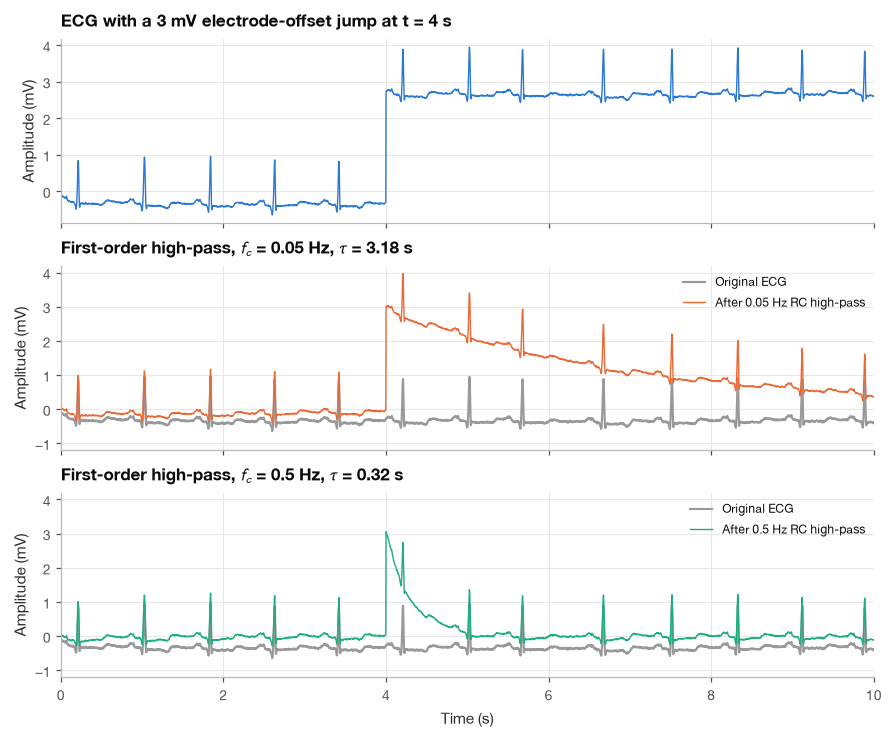

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), sharex=True)
axes[0].plot(t, x_step, color=C[0], lw=0.9)
axes[0].set(ylabel="Amplitude (mV)", title="ECG with a 3 mV electrode-offset jump at t = 4 s")
for ax, (fc, y), col in zip(axes[1:], filtered.items(), (C[1], C[2])):
    ax.plot(t, ecg, color="0.6", lw=1.4, label="Original ECG")
    ax.plot(t, y, color=col, lw=0.9, label=f"After {fc:g} Hz RC high-pass")
    ax.set(ylabel="Amplitude (mV)", title=f"First-order high-pass, $f_c$ = {fc:g} Hz, "
           f"$\\tau$ = {1 / (2 * np.pi * fc):.2f} s", ylim=(-1.2, 4.2))
    ax.legend(loc="upper right", fontsize=8)
axes[2].set(xlabel="Time (s)", xlim=(0, 10))
plt.show()

The 0.05 Hz filter barely touches the waveform but lets the jump linger: two seconds later most of it is still there. The 0.5 Hz filter removes the jump within about a second, but it also lowers the ST level of every beat by roughly 15 µV. In this healthy record that is small, but the shift grows with the area of the QRS complex, and a shift of 50 to 100 µV is the order of magnitude used to diagnose ischemia. [Section 12.2](../ch18_ecg_preprocessing/02_highpass_baseline_wander.ipynb) shows how digital filtering, which can be made zero-phase, escapes most of this compromise.

### Sampling and aliasing

The ADC measures the signal only at the instants $t = n T_s$, $T_s = 1/f_s$. A sinusoid of frequency $f$ above $f_s/2$ produces exactly the same samples as one at a lower frequency $|f - k f_s|$ for some integer $k$, so after sampling the two cannot be told apart. This is **aliasing**. The anti-aliasing low-pass filter exists to make sure nothing above $f_s/2$ reaches the ADC. A quick check shows how insidious the effect can be: muscle activity at 300 Hz, sampled at the MIT-BIH rate of 360 Hz, lands exactly at 60 Hz, where it would be mistaken for mains interference.

In [16]:
n = np.arange(3600)
emg_tone = np.cos(2 * np.pi * 300 * n / fs)               # 300 Hz sampled at 360 Hz
spectrum = np.abs(np.fft.rfft(emg_tone))
print(f"Apparent frequency after sampling: {np.fft.rfftfreq(n.size, 1 / fs)[spectrum.argmax()]:.1f} Hz"
      f"  (|300 - 360| = {abs(300 - 360)} Hz)")

Apparent frequency after sampling: 60.0 Hz  (|300 - 360| = 60 Hz)


[Chapter 6](../ch09_sampling/index.md) derives the sampling theorem, explains aliasing in the frequency domain, and treats quantization as noise.

(sec-1-3-7)=
## 1.3.7 Simulating an ECG Front End, Step by Step

I end the section by putting all the stages together and passing a real ECG through them. The simulation is not a circuit simulator; each stage is reduced to the equation we derived for it. But the numbers are realistic, and the exercise shows how the design decisions above interact.

### Step 1: Create a quasi-continuous input

An ADC samples a continuous signal, so to simulate one we need a signal defined much more finely in time than the final sampling rate. We take 10 s of record 100 and upsample it by a factor of ten to 3600 Hz. At this rate, our "analog" signal can contain frequencies up to 1800 Hz, far above the 180 Hz Nyquist frequency of the final 360 Hz recording.

In [17]:
UP = 10
fs_analog = fs * UP
ecg_analog = signal.resample_poly(ecg, UP, 1)                 # mV
t_analog = np.arange(ecg_analog.size) / fs_analog
print(f"Analog model: {ecg_analog.size} samples at {fs_analog} Hz ({t_analog[-1] + 1 / fs_analog:.1f} s)")

Analog model: 36000 samples at 3600 Hz (10.0 s)


### Step 2: Add what the electrodes and the environment add

On top of the ECG we place a 150 mV differential electrode offset, the 100 mV common-mode mains voltage of [Section 1.3.4](#sec-1-3-4), an electrode impedance mismatch of 20 kΩ against a common-mode input impedance of 100 MΩ (equation 1.20), and broadband noise of 15 µV RMS spread evenly up to 1800 Hz to stand for muscle activity and amplifier noise.

In [18]:
OFFSET_MV, VCM_MV, DZ, NOISE_UV = 150.0, 100.0, 20e3, 15.0
v_cm_analog = VCM_MV * np.cos(2 * np.pi * 60 * t_analog)
noise = 1e-3 * NOISE_UV * rng.standard_normal(t_analog.size)
v_d = ecg_analog + OFFSET_MV + v_cm_analog * DZ / Z_CM + noise       # mV, equation (1.20)
print(f"Mains converted to differential by the mismatch: {VCM_MV * DZ / Z_CM * 1000:.0f} µV amplitude")

Mains converted to differential by the mismatch: 20 µV amplitude


### Step 3: The instrumentation amplifier

The first stage has a gain of 10 and a CMRR of 100 dB, and its output can swing only between the supply rails, which we put at ±5 V. A single stage with the full gain of 1000 would be simpler, so we try that too.

In [19]:
RAIL = 5000.0                                                # mV


def amplifier(v_d, v_cm, gain, cmrr_db):
    """Differential amplifier, equation (1.17), with output clipped at the rails (mV)."""
    return np.clip(gain * (v_d + v_cm / 10 ** (cmrr_db / 20)), -RAIL, RAIL)


stage1 = amplifier(v_d, v_cm_analog, 10, 100)
one_stage = amplifier(v_d, v_cm_analog, 1000, 100)
print(f"Two-stage design, stage 1 output: {stage1.min() / 1000:.3f} V to {stage1.max() / 1000:.3f} V")
print(f"Single stage with gain 1000     : {100 * np.mean(np.abs(one_stage) >= RAIL):.0f} % of samples clipped")

Two-stage design, stage 1 output: 1.493 V to 1.509 V
Single stage with gain 1000     : 100 % of samples clipped


The single-stage design is hopeless: the 150 mV offset multiplied by 1000 asks for 150 V, and the output sits on the positive rail for the whole recording. No processing can recover an ECG from it. The first stage of the two-stage design stays near 1.5 V, comfortably inside the rails.

### Step 4: High-pass filter and second gain stage

We remove the offset with the 0.05 Hz RC high-pass of equation (1.23), started in steady state as if the device had been switched on some time ago, and then amplify by another 100.

In [20]:
stage2 = np.clip(100 * rc_highpass(stage1, 0.05, fs_analog), -RAIL, RAIL)
print(f"Stage 2 output: {stage2.min() / 1000:+.3f} V to {stage2.max() / 1000:+.3f} V (total gain 1000)")

Stage 2 output: -0.426 V to +1.257 V (total gain 1000)


### Step 5: Anti-aliasing filter, sampling and quantization

The anti-aliasing filter is a fourth-order Butterworth low-pass at 100 Hz, close to the passband used when the MIT-BIH tapes were digitized. We then keep every tenth sample, which is sampling at 360 Hz, and round to a 12-bit ADC with a range of ±2.5 V. To see what the anti-aliasing filter buys, we also sample the unfiltered stage-2 output.

In [21]:
def adc(v_mV, bits=12, full_scale_mV=2500.0):
    """Sample every UP-th value and quantize to a bipolar ADC (returns mV)."""
    q = 2 * full_scale_mV / 2**bits
    sampled = v_mV[::UP]
    return np.clip(np.round(sampled / q) * q, -full_scale_mV, full_scale_mV - q)


sos_aa = signal.butter(4, 100, "lowpass", fs=fs_analog, output="sos")
digital_aa = adc(signal.sosfilt(sos_aa, stage2))
digital_no_aa = adc(stage2)
print(f"ADC step: {5000 / 2**12:.3f} mV at the ADC = {5000 / 2**12 / 1000 * 1000:.2f} µV at the electrodes")

ADC step: 1.221 mV at the ADC = 1.22 µV at the electrodes


### Step 6: Compare the result with the original

To isolate the damage done by noise, interference, aliasing and quantization, we pass the clean ECG through exactly the same filters and gains, without anything added, and use that as the reference. Dividing the digital output by the total gain of 1000 refers it back to the electrodes.

In [22]:
reference = 100 * 10 * rc_highpass(ecg_analog, 0.05, fs_analog)
ref_aa = signal.sosfilt(sos_aa, reference)[::UP] / 1000
ref_no_aa = reference[::UP] / 1000
rows = []
for name, y, ref in (("with anti-aliasing", digital_aa / 1000, ref_aa),
                     ("without anti-aliasing", digital_no_aa / 1000, ref_no_aa)):
    err = y - ref                                                     # mV, referred to the input
    hum = abs(phasor_at(err, 60, fs))
    broadband = err - np.real(hum * np.exp(1j * (2 * np.pi * 60 * t + np.angle(phasor_at(err, 60, fs)))))
    rows.append({"chain": name, "total error RMS (µV)": round(1000 * np.sqrt(np.mean(err**2)), 2),
                 "60 Hz amplitude (µV)": round(1000 * hum, 2),
                 "broadband error RMS (µV)": round(1000 * np.sqrt(np.mean(broadband**2)), 2)})
pd.DataFrame(rows).set_index("chain")

,total error RMS (µV),60 Hz amplitude (µV),broadband error RMS (µV)
chain,,,
with anti-aliasing,18.27,20.82,10.81
without anti-aliasing,23.39,20.86,18.16


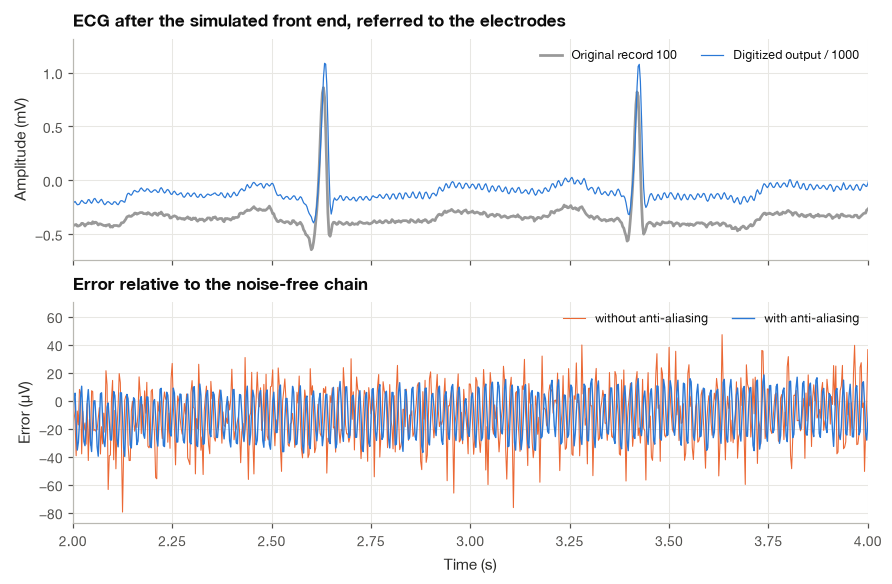

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True)
axes[0].plot(t, ecg, color="0.6", lw=1.8, label="Original record 100")
axes[0].plot(t, digital_aa / 1000, color=C[0], lw=0.8, label="Digitized output / 1000")
axes[0].set(ylabel="Amplitude (mV)", title="ECG after the simulated front end, referred to the electrodes")
axes[0].legend(loc="upper right", ncols=2, fontsize=8)
axes[1].plot(t, 1000 * (digital_no_aa / 1000 - ref_no_aa), color=C[1], lw=0.7, label="without anti-aliasing")
axes[1].plot(t, 1000 * (digital_aa / 1000 - ref_aa), color=C[0], lw=0.9, label="with anti-aliasing")
axes[1].set(xlabel="Time (s)", ylabel="Error (µV)", title="Error relative to the noise-free chain", xlim=(2, 4))
axes[1].legend(loc="upper right", ncols=2, fontsize=8)
plt.show()

The digitized ECG is indistinguishable from the original at the scale of the upper panel; the chain has done its job. The lower panel and the table show what is left. The 60 Hz component, about 21 µV, comes almost entirely from the electrode mismatch (20 µV) plus the amplifier's finite rejection (1 µV), exactly as the worst-case table predicted, and the anti-aliasing filter leaves it untouched because 60 Hz lies inside its passband. Removing it is a job for the notch filters of Section 15.4. The broadband error tells the anti-aliasing story. Without the filter, all of the noise between 180 and 1800 Hz folds back into the recorded band, and the broadband error is close to the full 15 µV of noise we injected. With the filter, only the noise below about 100 Hz survives, a little over a quarter of that amount. Once aliased, the extra noise would have been indistinguishable from genuine ECG content, which is why the filter has to sit in front of the ADC and cannot be replaced by digital filtering afterwards.

## Summary

A biomedical acquisition chain converts a physiological quantity into numbers through a sensor, an amplifier, analog filters and an ADC, and each stage can add artifacts that no later processing removes. Electrodes exchange ionic for electronic current and contribute a large DC offset and a frequency-dependent impedance, $Z_e = R_s + R_d/(1 + j\omega R_d C_d)$, that is highest at the low frequencies where the ECG lives; this is why amplifier input impedances must be many megaohms. Mains interference reaches the body as a common-mode voltage. A differential amplifier with gains $A_d$ and $A_{cm}$ refers it to the input as $v_{cm}/\text{CMRR}$, so 100 mV of common mode becomes 0.1 mV of hum at 60 dB but only 1 µV at 100 dB. Unequal electrode impedances convert common mode into a differential signal before any amplifier sees it, $v_{cm}\Delta Z/Z_{cm}$, and in practice this often sets the limit. Decibels express amplitude ratios as $20\log_{10}$ and power ratios as $10\log_{10}$, a direct consequence of power being proportional to amplitude squared, and an $N$-bit ADC offers about $6N$ dB of dynamic range. Splitting the gain into two stages around a high-pass filter lets the full ADC range serve the ECG instead of the electrode offset, and the choice of the high-pass cutoff trades baseline recovery against ST-segment fidelity.

The simulation in [Section 1.3.7](#sec-1-3-7) showed that a well-designed chain delivers an ECG that is faithful to within a few microvolts, apart from a residual of mains hum. The following section turns to the data files that such chains produce. Later chapters take up every stage in more depth: sampling and quantization in [Chapter 6](../ch09_sampling/index.md), filter design in Chapters 8 to 15, and the complete ECG recording system in [Section 11.2](../ch17_ecg/02_recording_the_ecg.ipynb).

## Exercises

1. A disposable pressure transducer (5 µV/V/mmHg) is driven with 4 V excitation. What voltage does it produce at 40 and at 200 mmHg? If it is followed by an amplifier with a gain of 500 and a 12-bit ADC with a range of ±2.5 V, what is the pressure resolution in mmHg?
2. Starting from equation (1.14), show that the imaginary part of $Z_e$ reaches its most negative value at $\omega = 1/(R_d C_d)$ and that this value is $-R_d/2$. Check your result numerically with `electrode_impedance` for the abraded-skin parameters.
3. Two amplifier channels have gains $A_1 = 200.2$ and $A_2 = 199.8$. Compute $A_d$, $A_{cm}$ and the CMRR in decibels. What common-mode voltage would produce an input-referred interference of 10 µV?
4. Express in decibels: a gain of 2500, a power ratio of 0.01, and the ratio between a 1.5 mV R wave and a 10 µV noise floor. How many ADC bits are needed for a dynamic range that covers the last ratio with a factor of four headroom?
5. Repeat the high-pass experiment of [Section 1.3.6](#sec-1-3-6) with a second-order Butterworth high-pass at 0.5 Hz (`signal.butter(2, 0.5, "highpass", ...)`). How do the recovery from the offset jump and the ST level change compared with the first-order filter?
6. In the front-end simulation of [Section 1.3.7](#sec-1-3-7), replace the 12-bit ADC by 10-bit and 16-bit converters and lower the anti-aliasing cutoff to 40 Hz. Report the broadband error in each case and explain which stage dominates the error budget. Then change the electrode mismatch to 2 kΩ and find the CMRR below which the amplifier, rather than the electrodes, becomes the main source of 60 Hz interference.

## Further Reading

{cite:t}`webster2010` is the standard reference for everything in this section, with detailed chapters on electrodes, biopotential amplifiers, the driven-right-leg circuit and the sources of interference; the original analysis of that circuit is by {cite:t}`winter1983`. {cite:t}`malmivuo1995` and {cite:t}`plonsey2007` treat the electrode–tissue interface and lead systems from the bioelectric side, and {cite:t}`kligfield2007` give the bandwidth and filtering recommendations for diagnostic electrocardiographs. The enzyme electrode that started continuous glucose monitoring was described by {cite:t}`clark1962`.